# Transmon dispersive shift

Differentiate the dispersive shift of a transmon, a qubit in a box cavity.

**Question.** A transmon qubit sits in a box cavity. One photon in the qubit
shifts the cavity's frequency by the dispersive shift $\chi$, which is how the qubit
is read out. How does $\chi$ change with the gap between the qubit's two pads, and
can `jax.grad` give that derivative from one solve?

The device is a teaching geometry, not a published one. Two thin metal pads on
a silicon chip are joined by a Josephson junction, modelled as a linear
7.5 nH inductor. The chip floats in the middle of a perfectly conducting box,
whose lowest mode is the readout.

gfem solves the two lowest modes of the linearized circuit. It then puts the
junction's cosine potential back on those modes
({py:func}`gfem.quantum.dressed_modes`) to get the anharmonicity and $\chi$. Both
steps are differentiable, and so is a move of the pad edges
({py:func}`gfem.shape.boundary_morph`). `jax.grad` chains them, from the gap to
$\chi$.

The page goes: the device → its two modes → $\chi$ from the dressed modes → the pad
gap as a parameter → the gradient and what it is made of → two checks, a
finite difference and a coarser mesh → one step towards a target $\chi$.

In [1]:
import time
import warnings
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
from matplotlib.colors import LogNorm

import gfem
from gfem import quantum, shape

pv.set_jupyter_backend("static")

GHz, MHz, mm, um = 1e9, 1e6, 1e-3, 1e-6
TWO_PI = 2 * np.pi
GOLD, PORT = "#d4a017", "#b5262f"  # the metal and the junction in the 3D views

## The device

The mesh, {download}`data/transmon.msh`, is in mm:

- the box, $|x| < 4$, $|y| < 17$, $|z| < 14$, with perfectly conducting walls
  (`"walls"`);
- the chip, silicon ($\varepsilon_r = 11.7$, lossless), $|x| < 2.5$, $|y| < 3$,
  $-0.4 < z < 0$;
- two pads on the chip, each 0.4 mm × 0.7 mm and 50 µm thick, their facing
  edges 300 µm apart. Each pad is a hole in the mesh with perfectly conducting
  faces (`"pad"`, `"pad_edge"`, and the lead stubs' `"stub_wall"` and
  `"stub_tip"`);
- a 0.1 mm-wide lead stub from each pad towards the centre, and between the two
  stub tips the junction: the 0.1 mm × 0.1 mm square `"junction"` on the chip
  surface.

The junction is a {py:class}`gfem.LumpedPort` with only an inductance,
$L_J = 7.5$ nH, oriented along +x. On an eigenmode solve it excites nothing: it
is part of the circuit, and its share of the mode's inductive energy is the
junction participation.

In [2]:
L_J = 7.5e-9  # H, the junction's inductance
METAL = ("pad", "pad_edge", "stub_wall", "stub_tip")  # the pads' faces


def transmon(mesh):
    return gfem.Model(
        mesh,
        materials={"vacuum": gfem.Material(), "chip": gfem.Material(eps_r=11.7)},
        boundaries=[gfem.PEC(surface) for surface in ("walls", *METAL)],
        ports=[gfem.LumpedPort("jj", "junction", "+x", inductance=L_J)],
    )


mesh = gfem.Mesh.from_gmsh(Path("data/transmon.msh"), length_unit="mm")
model = transmon(mesh)
model

Model(Mesh(1636 nodes, 7880 tetrahedra, volumes=['vacuum', 'chip'], surfaces=['junction', 'pad_edge', 'stub_wall', 'stub_tip', 'pad', 'chip_top', 'chip_side', 'walls'], length_unit='mm')
  materials:
    vacuum: Material()
    chip: Material(eps_r=11.7)
  boundaries:
    PEC(surface='walls')
    PEC(surface='pad')
    PEC(surface='pad_edge')
    PEC(surface='stub_wall')
    PEC(surface='stub_tip')
  ports:
    LumpedPort(name='jj', surface='junction', direction=(1.0, 0.0, 0.0), resistance=None, inductance=7.5e-09, capacitance=None, impedance=None))

The cavity with the chip (blue) and the pads (gold), then a close-up of the
pads with the junction (red) between the stub tips. The mesh is coarse on
purpose: 7880 tetrahedra, so the page runs in a few minutes.

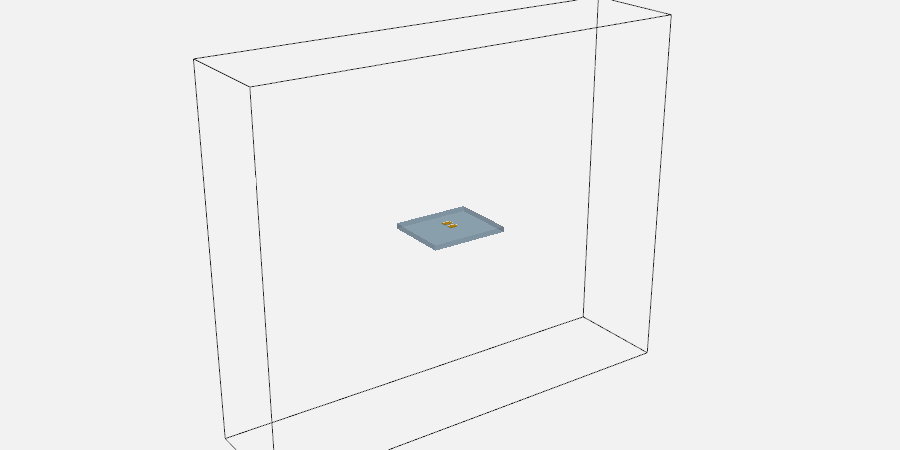

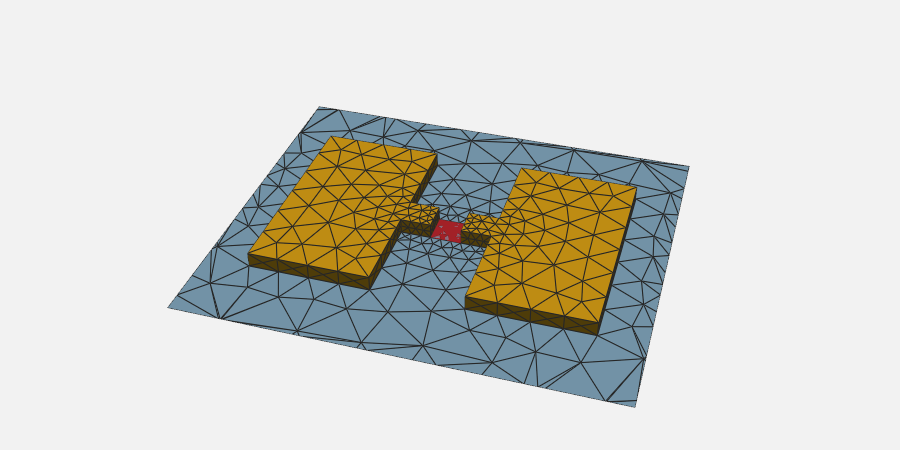

In [3]:
grid = pv.from_meshio(mesh.to_meshio())  # tetrahedra first, then triangles
grid.points /= mm


def part(region):
    """A region of the mesh as a PyVista grid, in mm."""
    cells = mesh.elements(region)
    if region in mesh.surfaces:
        cells = cells + len(mesh.tetrahedra)
    return grid.extract_cells(cells)


cavity = pv.Plotter(window_size=(900, 450))
cavity.add_mesh(part("walls").extract_feature_edges(), color="black")
cavity.add_mesh(part("chip"), color="#7fa7c9", opacity=0.5)
for surface in METAL:
    cavity.add_mesh(part(surface), color=GOLD)
cavity.view_vector((1.0, -0.7, 0.5), viewup=(0, 0, 1))
cavity.camera.zoom(1.4)
cavity.show()

near = (-0.7, 0.7, -0.6, 0.6, -0.15, 0.1)  # mm: the pads and the junction
closeup = pv.Plotter(window_size=(900, 450))
closeup.add_mesh(
    part("chip")
    .extract_surface(algorithm="dataset_surface")
    .clip_box(near, invert=False),
    color="#7fa7c9",
    show_edges=True,
)
for surface in METAL:
    closeup.add_mesh(part(surface), color=GOLD, show_edges=True)
closeup.add_mesh(part("junction"), color=PORT)
closeup.view_vector((0.3, -1.0, 0.8), viewup=(0, 0, 1))
closeup.camera.zoom(1.3)
closeup.show()

## Two modes

The two modes nearest 5.5 GHz, with the direct solver at its default accuracy.
They come nearest the target first: the qubit, then the readout.

In [4]:
problem = gfem.Eigenmode(target=5.5 * GHz, n_modes=2)
options = gfem.SolverOptions(order=2, linear_solver="direct")

start = time.perf_counter()
modes = gfem.solve(model, problem, options=options)
forward_seconds = time.perf_counter() - start

QUBIT, READOUT = 0, 1  # modes come nearest the target first
p = np.asarray(modes.participation["jj"])
chip = np.asarray(modes.bulk_participation["chip"])
print("mode     frequency   junction participation   chip participation")
for m, name in ((QUBIT, "qubit"), (READOUT, "readout")):
    f = float(modes.frequency[m]) / GHz
    print(f"{name:8s} {f:7.4f} GHz  {p[m]:+22.5f}  {chip[m]:19.3f}")
print(f"forward solve: {forward_seconds:.0f} s on this machine")

mode     frequency   junction participation   chip participation
qubit     5.6427 GHz                -0.96650                0.854
readout   6.7946 GHz                -0.00827                0.039
forward solve: 12 s on this machine


The qubit, at about 5.643 GHz, stores almost all its inductive energy in the
junction (participation −0.9665) and most of its electric energy in the chip.
The readout, the box's TE101 mode at about 6.795 GHz, barely touches the
junction (−0.00827). That small share is what couples the two. The
participation's sign is the junction's polarity along +x in the mode
({py:attr}`~gfem.EigenmodeResult.participation`); with one junction, it cancels
in every quantity below.

$|E|$ on two planes, darker where stronger, on a log scale per mode (each mode
stores 1 J of electric energy, see {py:mod}`gfem.conventions`). Left, the plane
through the middle of the pads ($z = 25$ µm), with the pads as holes. Right, the
plane $x = 0$
across the whole box. The qubit's field sits in the pad gap and dies off
within a few mm; the readout fills the box.

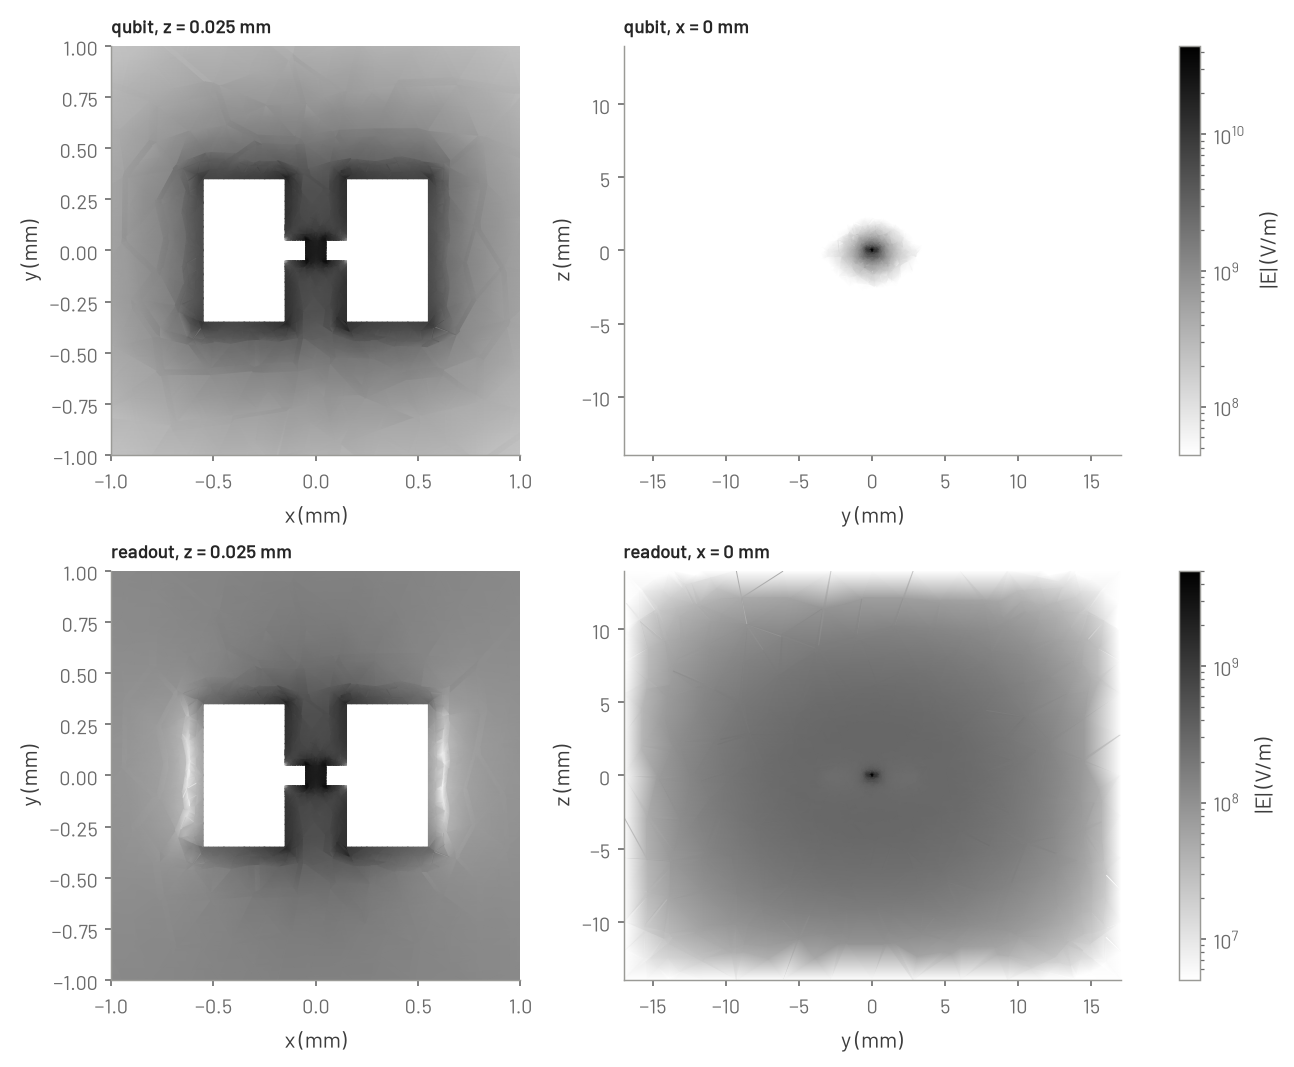

In [5]:
def cut(m, normal, origin):
    """|E| of mode m on a plane, as (in-plane coordinates in mm, triangles, |E|)."""
    field = modes.e_field(m).to_pyvista()
    field.points /= mm
    field["|E|"] = np.linalg.norm(field["E_real"] + 1j * field["E_imag"], axis=1)
    plane = field.slice(normal=normal, origin=origin).triangulate()
    axes = [i for i in range(3) if i != "xyz".index(normal)]
    triangles = plane.faces.reshape(-1, 4)[:, 1:]
    return plane.points[:, axes], triangles, plane["|E|"]


fig, axes = plt.subplots(2, 2, figsize=(9, 7), layout="constrained")
for row, (m, name) in enumerate(((QUBIT, "qubit"), (READOUT, "readout"))):
    for col, (normal, origin, labels, window) in enumerate(
        (
            ("z", (0, 0, 0.025), ("x (mm)", "y (mm)"), (-1, 1, -1, 1)),
            ("x", (0, 0, 0), ("y (mm)", "z (mm)"), (-17, 17, -14, 14)),
        )
    ):
        ax = axes[row, col]
        xy, triangles, e = cut(m, normal, origin)
        shown = ax.tripcolor(
            xy[:, 0],
            xy[:, 1],
            triangles,
            e,
            shading="gouraud",
            cmap="gray_r",
            norm=LogNorm(vmin=e.max() * 1e-3, vmax=e.max()),
        )
        ax.set(xlim=window[:2], ylim=window[2:], xlabel=labels[0], ylabel=labels[1])
        ax.set_aspect("equal")
        ax.set_title(f"{name}, {normal} = {origin['xyz'.index(normal)]} mm", fontsize=9)
        ax.grid(False)
    fig.colorbar(shown, ax=axes[row], label="|E| (V/m)")

## Dressed modes and the dispersive shift

The solve is linear: the junction is an inductor. A real junction's energy is
$-E_J \cos\varphi$, with $E_J = (\hbar/2e)^2 / L_J$, and its nonlinearity is what makes the
qubit a qubit. {py:func}`~gfem.quantum.dressed_modes` writes the junction's
phase $\varphi$ as a sum over the solved modes, weighted by their participations, puts
the full cosine back and diagonalizes the resulting Hamiltonian on a few Fock
levels per mode. From the dressed levels it reads, in rad/s:

- each mode's dressed frequency, the first transition;
- its anharmonicity $\alpha$, the second transition minus the first;
- the dispersive shift $\chi$ between two modes: the change of one mode's frequency
  per photon in the other.

All three are negative for a transmon. They are the full shift, not half of it,
with the opposite sign from some references: {py:mod}`gfem.conventions` gives
the conversions. Next to the diagonalization, `method="first_order"` gives the
closed-form perturbative values.

In [6]:
dressed = quantum.dressed_modes(modes.omega, modes.participation["jj"], inductance=L_J)
first = quantum.dressed_modes(
    modes.omega, modes.participation["jj"], inductance=L_J, method="first_order"
)


def mhz(omega):
    """An angular frequency, rad/s, in MHz."""
    return float(omega) / (TWO_PI * MHz)


f_dressed = np.asarray(dressed.omega) / (TWO_PI * GHz)
print(f"dressed qubit {f_dressed[QUBIT]:.4f} GHz, readout {f_dressed[READOUT]:.4f} GHz")
print(f"anharmonicity {mhz(dressed.anharmonicity[QUBIT]):.2f} MHz")
print(
    f"dispersive shift: {mhz(dressed.dispersive_shift[QUBIT, READOUT]):.4f} MHz "
    f"(diagonalized), {mhz(first.dispersive_shift[QUBIT, READOUT]):.4f} MHz "
    "(first order)"
)
print(f"smallest label overlap {float(dressed.overlap):.4f}")

dressed qubit 5.4645 GHz, readout 6.7930 GHz
anharmonicity -185.33 MHz
dispersive shift: -2.4960 MHz (diagonalized), -3.5169 MHz (first order)
smallest label overlap 0.9938


$\chi$ is about −2.496 MHz and $\alpha$ about −185.3 MHz. The first-order formula gives
−3.517 MHz, 1.4 times larger: at this detuning, $\chi$ is not small next to what
first order neglects. The dressed qubit, about 5.464 GHz, is lower than the
solve's linearized frequency by close to $|\alpha|$: quote the dressed one as the qubit
frequency. Each dressed level is labelled by the bare Fock state it overlaps
most; the smallest overlap, about 0.994, says the labels are clear. Below 1/2
the call raises {py:class}`gfem.ModeLabelError`.

## The pad gap as a parameter

{py:func}`gfem.shape.boundary_morph` moves the nodes of the facing pad edges,
`"pad_edge"`, along their outward normals; the rest of the mesh follows. A
negative displacement pulls an edge back into its pad, so moving each edge by
$-dg/2$ widens the gap by $dg$. The stub tips and the box walls are held
(`fixed=`), and so is the junction, as every port is: it keeps the size,
position and orientation it was imported with. The lead stubs stretch or shrink
to stay joined to the pads. Every other named surface (the pads' tops, the
stubs' sidewalls, the chip's faces) slides in its own plane.

The mesh is never regenerated, so the gap has a range. Below, the worst
element's quality ({py:func}`gfem.shape.quality`) against its imported value,
for gaps from 150 to 450 µm. Between 220 and 400 µm every element keeps at
least a third of its quality. Outside that range gfem warns
({py:class}`gfem.MeshQualityWarning`), and at 150 µm elements invert and the
morph raises {py:class}`gfem.MeshQualityError`: remesh at the new gap instead.

In [7]:
morph = shape.boundary_morph(model, "pad_edge", fixed=("stub_tip", "walls"))
ones = jnp.ones(morph.n_params)


def at_gap(dg):
    """The model with the pad gap widened by dg (m): each facing edge moves dg / 2."""
    return model.replace(mesh=morph(-dg / 2 * ones))


q0 = shape.quality(mesh)
print(f"{morph.n_params} moving nodes on 'pad_edge'")
for dg in (-150, -120, -80, -40, 40, 80, 100, 150):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            moved = at_gap(dg * um).mesh
        except gfem.MeshQualityError:
            print(f"gap {300 + dg} um: MeshQualityError (inverted elements)")
            continue
    worst = float(jnp.min(shape.quality(moved) / q0))
    warned = any(issubclass(w.category, gfem.MeshQualityWarning) for w in caught)
    note = ", MeshQualityWarning" if warned else ""
    print(
        f"gap {300 + dg} um: worst element at {worst:.2f} x its imported quality{note}"
    )

60 moving nodes on 'pad_edge'


gap 150 um: MeshQualityError (inverted elements)
gap 180 um: worst element at 0.09 x its imported quality, MeshQualityWarning


gap 220 um: worst element at 0.34 x its imported quality
gap 260 um: worst element at 0.65 x its imported quality
gap 340 um: worst element at 0.66 x its imported quality


gap 380 um: worst element at 0.44 x its imported quality
gap 400 um: worst element at 0.36 x its imported quality


gap 450 um: worst element at 0.23 x its imported quality, MeshQualityWarning


## The gradient

$\chi$ as a function of the gap change: solve the moved model, dress its modes, read
$\chi$. `jax.value_and_grad` returns $\chi$ and $d\chi/d(\mathrm{gap})$ from one solve and one backward
pass (the part of `jax.grad` that runs after the solve).

In [8]:
def chi(dg):
    """The dispersive shift (rad/s) between qubit and readout at gap 300 um + dg."""
    modes = gfem.solve(at_gap(dg), problem, options=options)
    dressed = quantum.dressed_modes(
        modes.omega, modes.participation["jj"], inductance=L_J
    )
    return dressed.dispersive_shift[QUBIT, READOUT]


start = time.perf_counter()
value, slope = jax.value_and_grad(chi)(0.0)
gradient_seconds = time.perf_counter() - start
PER_UM = TWO_PI * MHz / um  # rad/s per m -> MHz per um
print(f"chi = {mhz(value):.4f} MHz, d chi / d gap = {float(slope) / PER_UM:.4e} MHz/um")
print(
    f"value and gradient: {gradient_seconds:.0f} s, "
    f"against {forward_seconds:.0f} s for the solve alone, on this machine"
)

chi = -2.4960 MHz, d chi / d gap = -1.1093e-02 MHz/um
value and gradient: 16 s, against 12 s for the solve alone, on this machine


$\chi$ falls by about 1.109 × 10⁻² MHz per µm of gap ($d\chi/d(\mathrm{gap}) \approx -1.109 \times 10^{-2}$
MHz/µm): a wider gap couples the qubit more strongly to the box. The backward
pass takes a fraction of the solve's time.

What is the derivative made of? $\chi$ depends on the gap through the two mode
frequencies and through the two junction participations, which are
properties of the mode fields. `jax.vjp` exposes the chain: one solve, then one
backward pass for each part, with the other part's derivative set to zero.

In [9]:
def solved_modes(dg):
    modes = gfem.solve(at_gap(dg), problem, options=options)
    return modes.omega, modes.participation["jj"]


def chi_of(omega, participation):
    dressed = quantum.dressed_modes(omega, participation, inductance=L_J)
    return dressed.dispersive_shift[QUBIT, READOUT]


(omega, participation), through_solve = jax.vjp(solved_modes, 0.0)
_, through_dressing = jax.vjp(chi_of, omega, participation)
d_omega, d_participation = through_dressing(1.0)
(frequency_part,) = through_solve((d_omega, jnp.zeros_like(d_participation)))
(field_part,) = through_solve((jnp.zeros_like(d_omega), d_participation))
print(f"frequency part:  {float(frequency_part) / PER_UM:+.3e} MHz/um")
print(f"mode-field part: {float(field_part) / PER_UM:+.3e} MHz/um")
print(f"sum:             {float(frequency_part + field_part) / PER_UM:+.4e} MHz/um")

frequency part:  +1.503e-03 MHz/um
mode-field part: -1.260e-02 MHz/um
sum:             -1.1093e-02 MHz/um


Through the frequencies alone, $\chi$ would *rise* with the gap, by about
1.50 × 10⁻³ MHz/µm: the qubit moves up, away from the readout. The
participations pull the other way, by about −1.26 × 10⁻² MHz/µm, eight times
more. A model that differentiated only the frequencies, with the participations
held, would get the sign wrong. The mode-field part costs one extra linear solve
per mode the objective reads (gfem's adjoint of the eigenvector), on the
factorization the eigen solve already made.

## Against finite differences

Two more solves, at a gap 10 µm narrower and 10 µm wider, give a central
difference. Expect agreement to a few 10⁻⁴: that is the truncation error of a
second-order difference at this step, not an error of the gradient. gfem's own
tests check this gradient much more tightly (see {doc}`../verification`).

central difference (10 um): -1.1095e-02 MHz/um
relative difference from the gradient: 1.9e-04


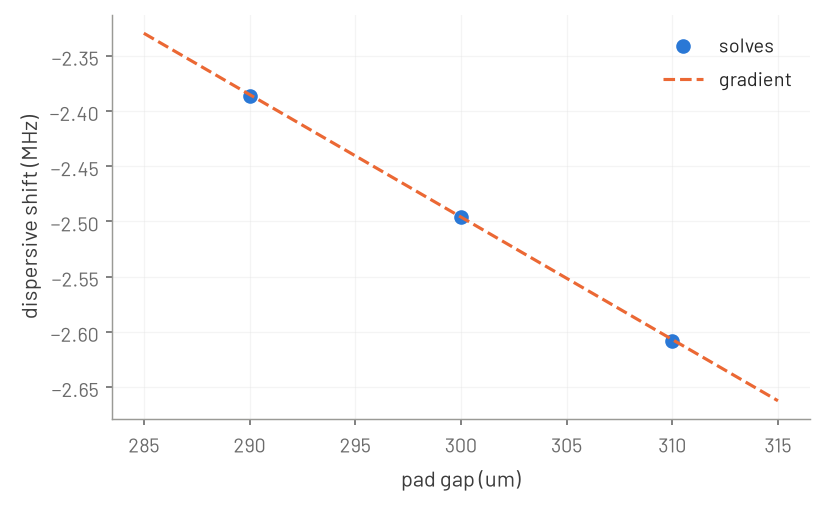

In [10]:
STEP = 10 * um
plus, minus = float(chi(STEP)), float(chi(-STEP))
central = (plus - minus) / (2 * STEP)
relative = abs(central - float(slope)) / abs(float(slope))
print(f"central difference ({STEP / um:.0f} um): {central / PER_UM:.4e} MHz/um")
print(f"relative difference from the gradient: {relative:.1e}")

gaps = 300 + np.array([-STEP, 0, STEP]) / um
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(gaps, [mhz(minus), mhz(value), mhz(plus)], "o", label="solves")
line = 300 + np.linspace(-15, 15, 3)
ax.plot(line, mhz(value) + float(slope) / PER_UM * (line - 300), label="gradient")
ax.set(xlabel="pad gap (um)", ylabel="dispersive shift (MHz)")
ax.legend()
ax.grid(alpha=0.3)

## A coarser mesh

The gradient is exact for the discrete problem on this mesh, and the mesh is
coarse. The same solve on a coarser mesh, {download}`data/transmon_coarse.msh`
(4308 tetrahedra), shows how far $\chi$ itself is from converged.

In [11]:
coarse_mesh = gfem.Mesh.from_gmsh(Path("data/transmon_coarse.msh"), length_unit="mm")
coarse = gfem.solve(transmon(coarse_mesh), problem, options=options)
chi_coarse = chi_of(coarse.omega, coarse.participation["jj"])
print(f"{len(coarse_mesh.tetrahedra)} against {len(mesh.tetrahedra)} tetrahedra")
print(f"qubit: {float(coarse.frequency[QUBIT]) / GHz:.4f} GHz on the coarse mesh")
print(f"chi: {mhz(chi_coarse):.4f} MHz coarse, {mhz(value):.4f} MHz")
print(f"change: {100 * (mhz(value) / mhz(chi_coarse) - 1):+.1f} %")

4308 against 7880 tetrahedra
qubit: 5.5353 GHz on the coarse mesh
chi: -2.2992 MHz coarse, -2.4960 MHz
change: +8.6 %


$\chi$ moves from about −2.299 MHz on the coarse mesh to −2.496 MHz on this one, by
about 9 %, and the qubit frequency by about 100 MHz. The numbers on this page are
those of a teaching mesh: for a design, refine around the pads and the junction
until $\chi$ stops moving, and optimize on that mesh.

## Use the gradient

One Newton step towards $\chi = -3.0$ MHz: the gap change that the gradient
predicts, then a solve there.

In [12]:
TARGET = -3.0 * TWO_PI * MHz
dg = (TARGET - float(value)) / float(slope)
reached = chi(dg)
print(f"Newton step: gap {300 + dg / um:.1f} um, chi {mhz(reached):.4f} MHz")

Newton step: gap 345.4 um, chi -3.0337 MHz


The step widens the gap to about 345 µm, inside the morph's range, and lands at
about −3.03 MHz: $\chi$ curves slightly over 45 µm, and a second step would close the
rest.

## Limits

- **One junction.** `dressed_modes` takes one junction's participations; a 2-D
  `participation` raises `ValueError`. For several junctions, there is no route
  in gfem yet.
- **The cosine on the solved modes only.** Modes you do not solve or do not pass
  add no Lamb shift and no dispersive shift: solve enough modes around the ones
  you read. The model has no charge dispersion, so it holds in the transmon
  regime ($E_J$ much larger than the charging energy), and it uses $\mathrm{Re}\,\omega$ only, so
  it holds for high-Q modes. A level whose label overlap is 1/2 or less raises
  `gfem.ModeLabelError`: move the modes apart, or leave the hybridized mode out.
- **The junction is held.** Under the morph the junction port keeps its imported
  geometry; the gap changes beside it. To change the junction itself, remesh.
- **A coarse mesh.** The gradient is that of the discrete problem on this mesh;
  $\chi$ itself moves by 9 % between the two meshes above. Check convergence before
  trusting an absolute number.
- **No loss.** The box and the pads are perfect conductors and the chip is
  lossless. Losses would make $\omega$ complex; the dressed modes still use its real
  part.
- **$L_J$ is fixed here.** It can be a gradient input too: build the port from a
  traced `L_J` inside the differentiated function and pass the same value to
  `dressed_modes`. gfem cannot tell if the two values differ, so pass one
  variable to both.

## Next

- {doc}`../recipes/eigenmode-gradient`: what is differentiable in an eigenmode
  solve, and the lumped values as inputs.
- {doc}`../recipes/shape-gradient`: boundary morphs, held ports and mesh quality.
- {doc}`../recipes/quantum-metrics`: the dressed modes' outputs and options,
  `L_J` as a design input, and the sheet participation of a kinetic-inductance
  film.
- {doc}`../recipes/loss-budget`: a mode's $1/Q$ from its loss channels, and the
  $T_1$ limit each one sets.
- {doc}`../recipes/measurements`: interface participation and the surface-loss
  Q of a mode.
- {py:mod}`gfem.quantum` reference: `dressed_modes` and `DressedModes`.

The last cell checks that the rounded values quoted on this page are the ones
computed above.

In [13]:
f_qubit, f_readout = np.asarray(modes.frequency) / GHz
np.testing.assert_equal(round(f_qubit, 3), 5.643)
np.testing.assert_equal(round(f_readout, 3), 6.795)
np.testing.assert_equal(round(p[QUBIT], 4), -0.9665)
np.testing.assert_equal(round(p[READOUT], 5), -0.00827)
np.testing.assert_equal(round(mhz(value), 3), -2.496)
np.testing.assert_equal(round(mhz(first.dispersive_shift[QUBIT, READOUT]), 3), -3.517)
np.testing.assert_equal(round(mhz(dressed.anharmonicity[QUBIT]), 1), -185.3)
np.testing.assert_equal(round(f_dressed[QUBIT], 3), 5.464)
np.testing.assert_equal(round(float(dressed.overlap), 3), 0.994)
np.testing.assert_equal(round(float(slope) / PER_UM * 1e2, 3), -1.109)
np.testing.assert_equal(round(float(frequency_part) / PER_UM * 1e3, 2), 1.50)
np.testing.assert_equal(round(float(field_part) / PER_UM * 1e2, 2), -1.26)
np.testing.assert_equal(round(mhz(chi_coarse), 3), -2.299)
np.testing.assert_equal(round(mhz(reached), 2), -3.03)
np.testing.assert_array_less(relative, 1e-3)  # the difference's truncation